In [ ]:
import pandas as pd
import numpy as np

import matplotlib.pyplot as plt
import seaborn as sns

from pandas_datareader.data import DataReader
import yfinance as yf
from pandas_datareader import data as pdr
#loading libraries to read stock data
#yf.pdr_override()

from datetime import datetime

alist = ['AAPL', 'GOOG', 'MSFT', 'AMZN']

#start and end dates (start of 2022 to end of 2024)
start_date = datetime(2022, 1, 1)
end_date = datetime(2024, 12, 31)

#format stocks better
for stock in alist:
    globals()[stock] = yf.download(stock, start_date, end_date, auto_adjust= False)


company_list = [AAPL, GOOG, MSFT, AMZN]
company_name = ["APPLE", "GOOGLE", "MICROSOFT", "AMAZON"]

for company, comp_name in zip(company_list, company_name):
    company["company_name"] = comp_name

df = pd.concat(company_list, axis=0)
df.tail(10)

[*********************100%***********************]  1 of 1 completed
[*********************100%***********************]  1 of 1 completed
[*********************100%***********************]  1 of 1 completed
[*********************100%***********************]  1 of 1 completed


Price      Adj Close Close High  Low Open Volume company_name Adj Close Close  \
Ticker          AAPL  AAPL AAPL AAPL AAPL   AAPL                   GOOG  GOOG   
Date                                                                            
2024-12-16       NaN   NaN  NaN  NaN  NaN    NaN       AMAZON       NaN   NaN   
2024-12-17       NaN   NaN  NaN  NaN  NaN    NaN       AMAZON       NaN   NaN   
2024-12-18       NaN   NaN  NaN  NaN  NaN    NaN       AMAZON       NaN   NaN   
2024-12-19       NaN   NaN  NaN  NaN  NaN    NaN       AMAZON       NaN   NaN   
2024-12-20       NaN   NaN  NaN  NaN  NaN    NaN       AMAZON       NaN   NaN   
2024-12-23       NaN   NaN  NaN  NaN  NaN    NaN       AMAZON       NaN   NaN   
2024-12-24       NaN   NaN  NaN  NaN  NaN    NaN       AMAZON       NaN   NaN   
2024-12-26       NaN   NaN  NaN  NaN  NaN    NaN       AMAZON       NaN   NaN   
2024-12-27       NaN   NaN  NaN  NaN  NaN    NaN       AMAZON       NaN   NaN   
2024-12-30       NaN   NaN  NaN  NaN  NaN    NaN       AMAZON       NaN   NaN   

Price      High  ...       Low Open Volume   Adj Close       Close  \
Ticker     GOOG  ... MSFT MSFT MSFT   MSFT        AMZN        AMZN   
Date             ...                                                 
2024-12-16  NaN  ...  NaN  NaN  NaN    NaN  232.929993  232.929993   
2024-12-17  NaN  ...  NaN  NaN  NaN    NaN  231.149994  231.149994   
2024-12-18  NaN  ...  NaN  NaN  NaN    NaN  220.520004  220.520004   
2024-12-19  NaN  ...  NaN  NaN  NaN    NaN  223.289993  223.289993   
2024-12-20  NaN  ...  NaN  NaN  NaN    NaN  224.919998  224.919998   
2024-12-23  NaN  ...  NaN  NaN  NaN    NaN  225.059998  225.059998   
2024-12-24  NaN  ...  NaN  NaN  NaN    NaN  229.050003  229.050003   
2024-12-26  NaN  ...  NaN  NaN  NaN    NaN  227.050003  227.050003   
2024-12-27  NaN  ...  NaN  NaN  NaN    NaN  223.750000  223.750000   
2024-12-30  NaN  ...  NaN  NaN  NaN    NaN  221.300003  221.300003   

Price             High         Low        Open      Volume  
Ticker            AMZN        AMZN        AMZN        AMZN  
Date                                                        
2024-12-16  233.000000  228.009995  230.229996  37552100.0  
2024-12-17  232.729996  227.850006  232.389999  35948100.0  
2024-12-18  231.399994  220.110001  230.770004  43281400.0  
2024-12-19  226.089996  222.919998  224.910004  39918700.0  
2024-12-20  226.210007  218.729996  219.839996  88279200.0  
2024-12-23  226.880005  223.899994  225.009995  28070000.0  
2024-12-24  229.139999  226.130005  226.940002  15007500.0  
2024-12-26  228.500000  226.669998  228.500000  16146700.0  
2024-12-27  226.029999  220.899994  225.600006  27367100.0  
2024-12-30  223.000000  218.429993  220.059998  28321200.0  

[10 rows x 25 columns]

In [ ]:
df_Aclose = AAPL.xs('Close', level='Price', axis=1) # Replace 'st' with 'AAPL' which contains the dataframe you're working with
# Convert the 'Close' DataFrame into a NumPy array
df_Aclose

Ticker,AAPL
Date,
2022-01-03,182.009995
2022-01-04,179.699997
2022-01-05,174.919998
2022-01-06,172.000000
2022-01-07,172.169998
...,...
2024-12-23,255.270004
2024-12-24,258.200012
2024-12-26,259.019989


In [ ]:
ds = df_Aclose.to_numpy()
ds

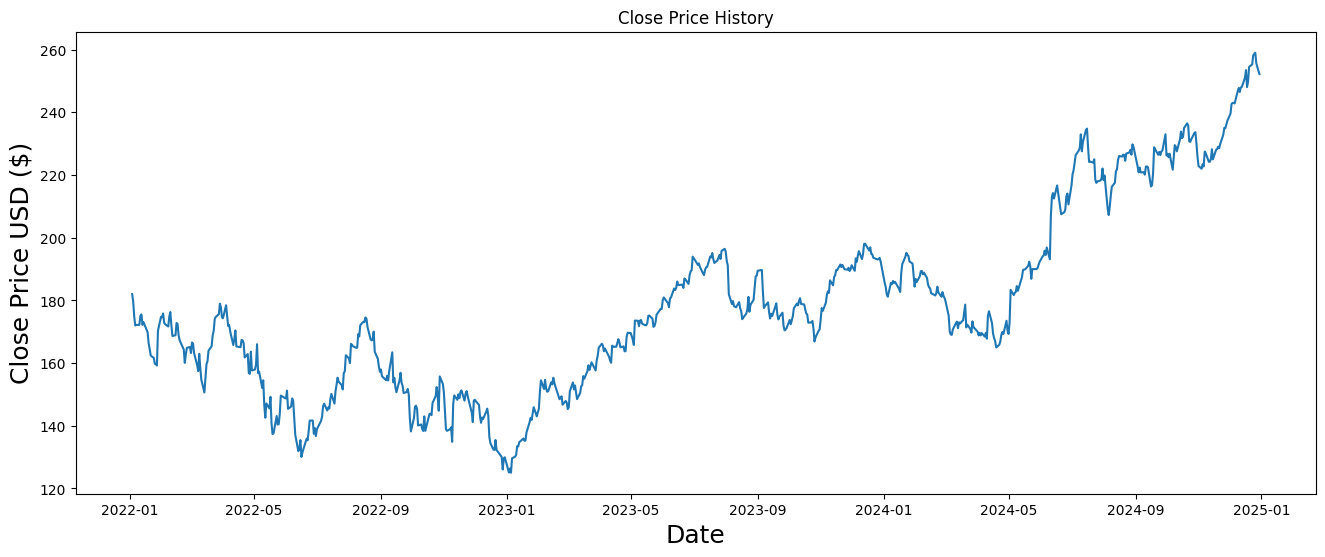

In [ ]:
plt.figure(figsize=(16,6))
plt.title('Close Price History')
plt.plot(df['Close'])
plt.xlabel('Date', fontsize=18)
plt.ylabel('Close Price USD ($)', fontsize=18)
plt.show()

In [ ]:
dataset = ds # removing .values
# Get the number of rows to train the model on
training_data_len = int(np.ceil( len(dataset) * .95 ))

training_data_len

715

In [ ]:
from sklearn.preprocessing import MinMaxScaler

scaler = MinMaxScaler(feature_range=(0,1))
scaled_data = scaler.fit_transform(dataset)

scaled_data

array([[4.25298516e-01],
       [4.08059727e-01],
       [3.72388092e-01],
       [3.50597060e-01],
       [3.51865703e-01],
       [3.52014989e-01],
       [3.73582150e-01],
       [3.76940336e-01],
       [3.52014989e-01],
       [3.58582190e-01],
       [3.34179171e-01],
       [3.07537324e-01],
       [2.94701493e-01],
       [2.79029919e-01],
       [2.73134333e-01],
       [2.59403016e-01],
       [2.58731401e-01],
       [2.55223929e-01],
       [3.38134386e-01],
       [3.71343321e-01],
       [3.70074678e-01],
       [3.79253751e-01],
       [3.57313433e-01],
       [3.53507503e-01],
       [3.48059774e-01],
       [3.71716478e-01],
       [3.82537351e-01],
       [3.51492546e-01],
       [3.25522427e-01],
       [3.27313513e-01],
       [3.56492533e-01],
       [3.54701561e-01],
       [3.27313513e-01],
       [3.15522454e-01],
       [2.93283678e-01],
       [2.61567259e-01],
       [2.81492619e-01],
       [2.97238893e-01],
       [2.99253737e-01],
       [2.84925392e-01],


In [ ]:
train_data = scaled_data[0:int(training_data_len), :]
# Split the data into x_train and y_train data sets
x_train = []
y_train = []

for i in range(60, len(train_data)):
    x_train.append(train_data[i-60:i, 0])
    y_train.append(train_data[i, 0])
    if i<= 61:
        print(x_train)
        print(y_train)
        print()

# Convert the x_train and y_train to numpy arrays
x_train, y_train = np.array(x_train), np.array(y_train)

# Reshape the data
x_train = np.reshape(x_train, (x_train.shape[0], x_train.shape[1], 1))
# x_train.shape

[array([0.42529852, 0.40805973, 0.37238809, 0.35059706, 0.3518657 ,
       0.35201499, 0.37358215, 0.37694034, 0.35201499, 0.35858219,
       0.33417917, 0.30753732, 0.29470149, 0.27902992, 0.27313433,
       0.25940302, 0.2587314 , 0.25522393, 0.33813439, 0.37134332,
       0.37007468, 0.37925375, 0.35731343, 0.3535075 , 0.34805977,
       0.37171648, 0.38253735, 0.35149255, 0.32552243, 0.32731351,
       0.35649253, 0.35470156, 0.32731351, 0.31552245, 0.29328368,
       0.26156726, 0.28149262, 0.29723889, 0.29925374, 0.28492539,
       0.31000002, 0.30753732, 0.28470152, 0.25582096, 0.24194036,
       0.28305972, 0.25000007, 0.22171642, 0.19104478, 0.224403  ,
       0.25798509, 0.26567165, 0.29074628, 0.30119411, 0.32686577,
       0.3372389 , 0.36604488, 0.37089558, 0.37746278, 0.40253741])]
[np.float64(0.3936567957668473)]

[array([0.42529852, 0.40805973, 0.37238809, 0.35059706, 0.3518657 ,
       0.35201499, 0.37358215, 0.37694034, 0.35201499, 0.35858219,
       0.33417917, 0.307

In [ ]:
from keras.models import Sequential
from keras.layers import Dense, LSTM

# Build the LSTM model
model = Sequential()
model.add(LSTM(128, return_sequences=True, input_shape= (x_train.shape[1], 1)))
model.add(LSTM(64, return_sequences=False))
model.add(Dense(25))
model.add(Dense(1))

# Compile the model
model.compile(optimizer='adam', loss='mean_squared_error')

# Train the model
model.fit(x_train, y_train, batch_size=1, epochs=1)

/usr/local/lib/python3.11/dist-packages/keras/src/layers/rnn/rnn.py:200: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(**kwargs)


655/655 ━━━━━━━━━━━━━━━━━━━━ 39s 54ms/step - loss: 0.0056


In [ ]:
from sklearn.metrics import mean_squared_error
from sklearn.metrics import mean_absolute_error

test_data = scaled_data[training_data_len - 60: , :]
# Create the data sets x_test and y_test
x_test = []
y_test = dataset[training_data_len:, :]
for i in range(60, len(test_data)):
    x_test.append(test_data[i-60:i, 0])

# Convert the data to a numpy array
x_test = np.array(x_test)

# Reshape the data
x_test = np.reshape(x_test, (x_test.shape[0], x_test.shape[1], 1 ))

# Get the models predicted price values
predictions = model.predict(x_test)
predictions = scaler.inverse_transform(predictions)

# Get the root mean squared error (RMSE)
mae = mean_absolute_error(y_test, predictions)
mse = mean_squared_error(y_test, predictions)
rmse = np.sqrt(np.mean(((predictions - y_test) ** 2)))

print('', rmse, '\n', mae, '\n', mse)


2/2 ━━━━━━━━━━━━━━━━━━━━ 0s 54ms/step
 5.263301207533011 
 4.572760917044975 
 27.702339601218448


<ipython-input-42-2603e126ad48>:3: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  valid['Predictions'] = predictions


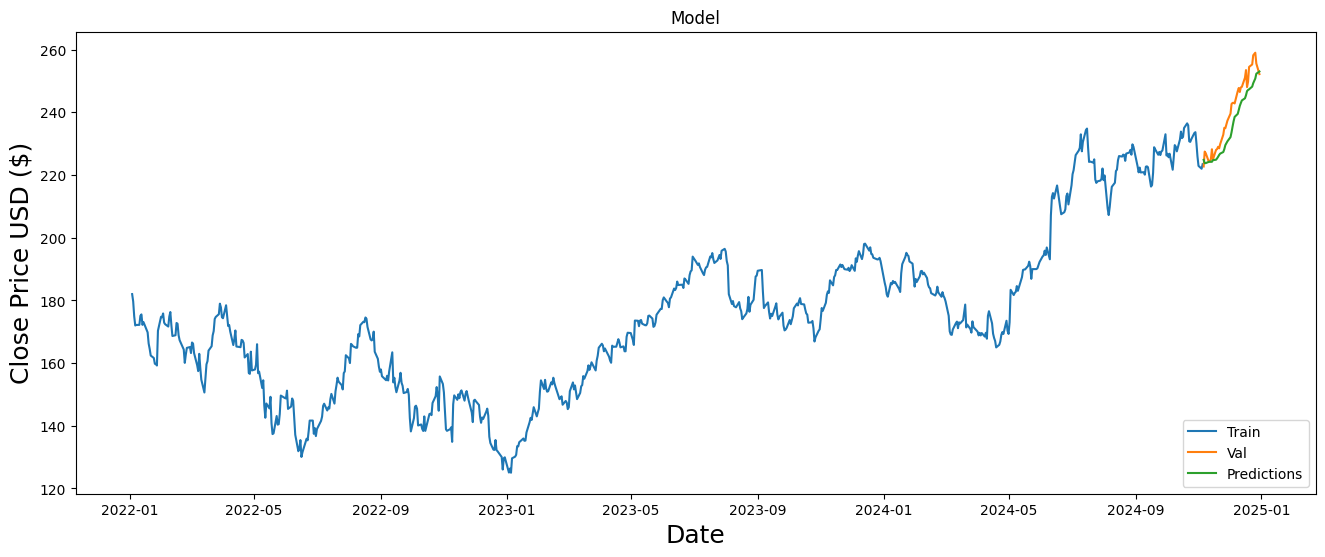

In [ ]:
train = df[:training_data_len] # Use the original DataFrame 'df' which has the 'Close' column
valid = df[training_data_len:] # Use the original DataFrame 'df' which has the 'Close' column
valid['Predictions'] = predictions
# Visualize the data
plt.figure(figsize=(16,6))
plt.title('Model')
plt.xlabel('Date', fontsize=18)
plt.ylabel('Close Price USD ($)', fontsize=18)
plt.plot(train['Close']) # Now 'train' has the 'Close' column
plt.plot(valid[['Close', 'Predictions']]) # Now 'valid' has the 'Close' column
plt.legend(['Train', 'Val', 'Predictions'], loc='lower right')
plt.show()

In [ ]:
valid

Price,Adj Close,Close,High,Low,Open,Volume,Predictions
Ticker,AAPL,AAPL,AAPL,AAPL,AAPL,AAPL,
Date,,,,,,,
2024-11-06,222.230896,222.720001,226.070007,221.190002,222.610001,54561100,224.828934
2024-11-07,226.980438,227.479996,227.880005,224.570007,224.630005,42137700,223.774216
2024-11-08,226.710739,226.960007,228.660004,226.410004,227.169998,38328800,223.800690
2024-11-11,223.983734,224.229996,225.699997,221.500000,225.000000,42005600,224.199966
2024-11-12,223.983734,224.229996,225.589996,223.360001,224.550003,40398300,224.278259
2024-11-13,224.872757,225.119995,226.649994,222.759995,224.009995,48566200,224.213242
2024-11-14,227.969360,228.220001,228.869995,225.000000,225.020004,44923900,224.225708
2024-11-15,224.752884,225.000000,226.919998,224.270004,226.399994,47923700,224.749405
